# Retail Promotion Effectiveness & Discount Sensitivity Analysis
## 03 — Discount Sensitivity

Operationalizes sensitivity as observed quantity response and household discount exposure. It is not price elasticity because regular price, random assignment, and full confounders are unavailable.

## Imports

In [1]:
from pathlib import Path
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest
warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_columns', 50)

## Config (file paths, plotting style, and reproducibility)

In [2]:
def find_project_root():
    current = Path.cwd().resolve()
    for candidate in (current, *current.parents):
        if (candidate / 'README.md').exists():
            return candidate
    raise FileNotFoundError('Run from the repository or notebooks directory.')
PROJECT_ROOT = find_project_root()
RAW_DIR = PROJECT_ROOT / 'data' / 'raw'
PROCESSED_DIR = PROJECT_ROOT / 'data' / 'processed'
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(PROJECT_ROOT / 'src'))
from data_utils import add_bar_labels, add_promotion_fields, bootstrap_ci, summarize_frame
RANDOM_STATE = 42
ALPHA = 0.05
POWER = 0.80
plt.style.use('seaborn-v0_8')
sns.set_palette('husl')

## Data Cleaning and Preprocessing

Only required-field missingness and exact duplicates are removed after counts. Extreme quantities are retained and robust summaries are emphasized.

In [3]:
df=pd.read_csv(PROCESSED_DIR/'transaction_product_analysis.csv.gz',low_memory=False)

In [4]:
summarize_frame('discount sensitivity input',df,'QUANTITY')

discount sensitivity input row count: 2,595,732
discount sensitivity input column count: 23
discount sensitivity input null counts:
household_key               0
BASKET_ID                   0
DAY                         0
PRODUCT_ID                  0
QUANTITY                    0
SALES_VALUE                 0
STORE_ID                    0
RETAIL_DISC                 0
TRANS_TIME                  0
WEEK_NO                     0
COUPON_DISC                 0
COUPON_MATCH_DISC           0
MANUFACTURER                0
DEPARTMENT                  0
BRAND                       0
COMMODITY_DESC              0
SUB_COMMODITY_DESC          0
CURR_SIZE_OF_PRODUCT        0
discount_amount             0
gross_value_proxy           0
discount_rate           10138
promotion_type              0
is_discounted               0


discount sensitivity input exact duplicate count: 0
discount sensitivity input DataFrame info:
<class 'pandas.DataFrame'>
RangeIndex: 2595732 entries, 0 to 2595731
Data columns (total 23 columns):
 #   Column                Dtype  
---  ------                -----  
 0   household_key         int64  
 1   BASKET_ID             int64  
 2   DAY                   int64  
 3   PRODUCT_ID            int64  
 4   QUANTITY              int64  
 5   SALES_VALUE           float64
 6   STORE_ID              int64  
 7   RETAIL_DISC           float64
 8   TRANS_TIME            int64  
 9   WEEK_NO               int64  
 10  COUPON_DISC           float64
 11  COUPON_MATCH_DISC     float64
 12  MANUFACTURER          int64  
 13  DEPARTMENT            str    
 14  BRAND                 str    
 15  COMMODITY_DESC        str    
 16  SUB_COMMODITY_DESC    str    
 17  CURR_SIZE_OF_PRODUCT  str    
 18  discount_amount       float64
 19  gross_value_proxy     float64
 20  discount_rate         float6

In [5]:
required=['household_key','PRODUCT_ID','DEPARTMENT','QUANTITY','SALES_VALUE','discount_amount','discount_rate','is_discounted']
print('Rows missing required fields:',f'{df[required].isna().any(axis=1).sum():,}')
analysis_df=df.dropna(subset=required).drop_duplicates().copy()
print('Rows after dropna and exact deduplication:',f'{len(analysis_df):,}')
print('No guessed row ID was used.')

Rows missing required fields: 10,138


Rows after dropna and exact deduplication: 2,585,594
No guessed row ID was used.


## Column Description

One line per required field with observed type.

In [6]:
display(pd.DataFrame({'column':required,'type':analysis_df[required].dtypes.astype(str).values}))

,column,type
0,household_key,int64
1,PRODUCT_ID,int64
2,DEPARTMENT,str
3,QUANTITY,int64
4,SALES_VALUE,float64
5,discount_amount,float64
6,discount_rate,float64
7,is_discounted,bool


## EDA

Response scores compare mean quantity on discounted and non-discounted lines. Products require at least 100 lines in each condition. These are screening statistics, not causal elasticities.

In [7]:
dept=analysis_df.groupby(['DEPARTMENT','is_discounted']).agg(lines=('PRODUCT_ID','size'),mean_quantity=('QUANTITY','mean'),median_quantity=('QUANTITY','median')).reset_index()
dept_wide=dept.pivot(index='DEPARTMENT',columns='is_discounted',values=['lines','mean_quantity','median_quantity']); dept_wide.columns=[f'{a}_{"discounted" if b else "not_discounted"}' for a,b in dept_wide.columns]; dept_wide=dept_wide.dropna().reset_index()
dept_wide['quantity_response_pct']=100*(dept_wide.mean_quantity_discounted/dept_wide.mean_quantity_not_discounted-1)
display(dept_wide.sort_values('lines_discounted',ascending=False).head(15))

,DEPARTMENT,lines_not_discounted,lines_discounted,mean_quantity_not_discounted,mean_quantity_discounted,median_quantity_not_discounted,median_quantity_discounted,quantity_response_pct
11,GROCERY,686206.0,957098.0,1.306374,1.356272,1.0,1.0,3.819525e+00
6,DRUG GM,190114.0,85796.0,1.204667,1.454788,1.0,1.0,2.076271e+01
15,MEAT-PCKGD,40962.0,70774.0,1.194961,1.401645,1.0,1.0,1.729625e+01
23,PRODUCE,194000.0,61921.0,1.224871,1.330146,1.0,1.0,8.594810e+00
14,MEAT,40670.0,47581.0,1.253184,1.432189,1.0,1.0,1.428403e+01
5,DELI,36142.0,26482.0,1.076946,1.061174,1.0,1.0,-1.464591e+00
13,KIOSK-GAS,1793.0,20266.0,63.078081,10911.960328,1.0,10549.5,1.719913e+04
18,NUTRITION,17660.0,14437.0,1.263307,1.450648,1.0,1.0,1.482939e+01
19,PASTRY,24952.0,12956.0,1.360292,1.224761,1.0,1.0,-9.963380e+00
27,SEAFOOD-PCKGD,3871.0,7308.0,1.135882,1.314313,1.0,1.0,1.570857e+01


In [8]:
prod=analysis_df.groupby(['PRODUCT_ID','is_discounted']).QUANTITY.agg(['size','mean']).reset_index()
prod_wide=prod.pivot(index='PRODUCT_ID',columns='is_discounted',values=['size','mean']); prod_wide.columns=[f'{a}_{"discounted" if b else "not_discounted"}' for a,b in prod_wide.columns]; prod_wide=prod_wide.dropna()
supported=prod_wide[(prod_wide.size_discounted>=100)&(prod_wide.size_not_discounted>=100)].copy(); supported['quantity_response_pct']=100*(supported.mean_discounted/supported.mean_not_discounted-1)
print('Supported products:',f'{len(supported):,}'); display(supported.quantity_response_pct.describe().to_frame('value'))

Supported products: 748


,value
count,748.000000
mean,11.792771
std,15.441041
min,-31.528967
25%,1.786960
50%,7.565520
75%,16.596059
max,105.945122


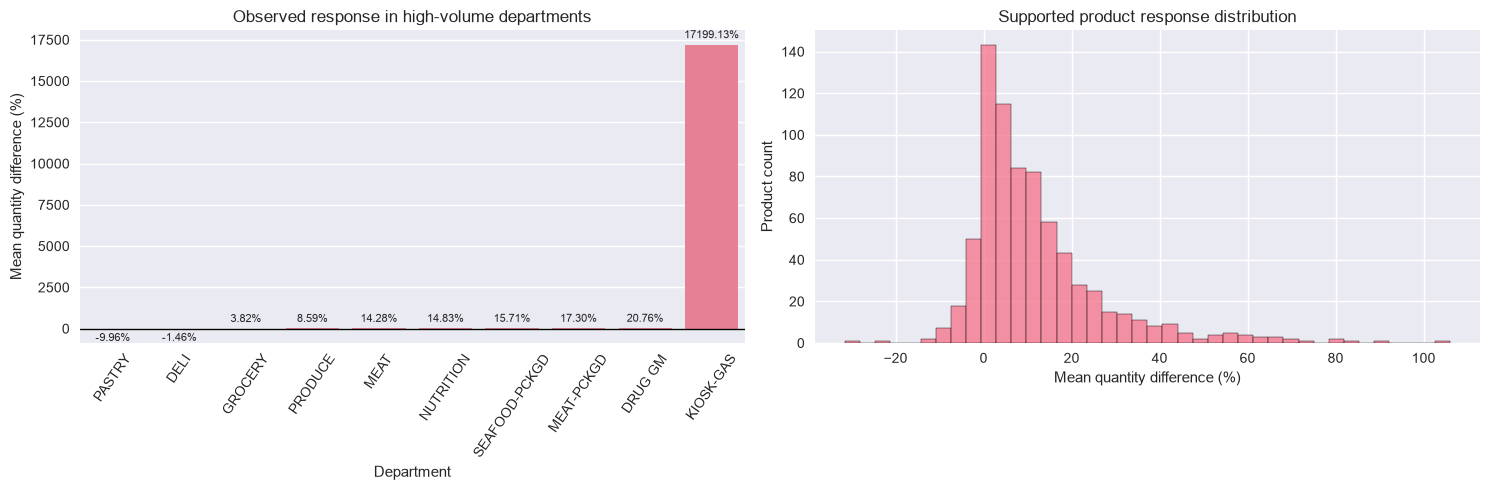

In [9]:
top=dept_wide.nlargest(10,'lines_discounted').sort_values('quantity_response_pct')
fig,axes=plt.subplots(1,2,figsize=(15,5))
sns.barplot(data=top,x='DEPARTMENT',y='quantity_response_pct',ax=axes[0]); axes[0].axhline(0,color='black',lw=1); axes[0].set(title='Observed response in high-volume departments',xlabel='Department',ylabel='Mean quantity difference (%)'); axes[0].tick_params(axis='x',rotation=55); add_bar_labels(axes[0],True)
sns.histplot(data=supported,x='quantity_response_pct',bins=40,ax=axes[1]); axes[1].set(title='Supported product response distribution',xlabel='Mean quantity difference (%)',ylabel='Product count')
plt.tight_layout(); plt.show()

In [10]:
households=analysis_df.groupby('household_key').agg(lines=('PRODUCT_ID','size'),mean_quantity=('QUANTITY','mean'),total_sales=('SALES_VALUE','sum'),discount_exposure=('is_discounted','mean'),mean_discount_rate=('discount_rate','mean')).reset_index()
households['exposure_segment']=pd.qcut(households.discount_exposure,4,labels=['Low','Medium-low','Medium-high','High'],duplicates='drop')
segments=households.groupby('exposure_segment',observed=True).agg(households=('household_key','size'),median_quantity=('mean_quantity','median'),median_sales=('total_sales','median'),mean_exposure=('discount_exposure','mean')).reset_index(); segments['household_share_pct']=100*segments.households/segments.households.sum(); display(segments)

,exposure_segment,households,median_quantity,median_sales,mean_exposure,household_share_pct
0,Low,625,1.628571,1772.91,0.381855,25.0
1,Medium-low,625,11.158879,2363.78,0.471220,25.0
2,Medium-high,625,17.590361,2377.09,0.531951,25.0
3,High,625,35.213092,2124.43,0.629197,25.0


## Problem Statement

Identify product, department, and household patterns that can prioritize future tests while using the household as the independent inferential unit.

## Question 1 — Which products and departments show greater observed discount response?

In [11]:
sensitivity_summary=pd.DataFrame({'metric':['supported_products','median_product_response_pct','highest_response_high_volume_department','department_response_pct'],'value':[len(supported),supported.quantity_response_pct.median(),top.iloc[-1].DEPARTMENT,top.iloc[-1].quantity_response_pct]}); display(sensitivity_summary); sensitivity_summary.to_csv(PROCESSED_DIR/'discount_sensitivity_summary.csv',index=False)

,metric,value
0,supported_products,748
1,median_product_response_pct,7.56552
2,highest_response_high_volume_department,KIOSK-GAS
3,department_response_pct,17199.131617


## Question 2 — Is household discount exposure associated with mean quantity per line?

**Objective:** test a monotonic household-level association. $H_0$: Spearman $\rho=0$. $H_1$: $\rho\ne0$. $\alpha=0.05$; power $=0.80$.

Fisher-transform planning uses $n=3+((z_{1-\alpha/2}+z_{1-\beta})/\operatorname{arctanh}(\rho_{MDE}))^2$. A minimum detectable $|\rho|=0.10$ is a small planning target, not an observed effect. Spearman is chosen for bounded/skewed variables.

In [12]:
def sample_size_correlation(rho,alpha=.05,power=.80):
    return int(np.ceil(3+((stats.norm.ppf(1-alpha/2)+stats.norm.ppf(power))/np.arctanh(abs(rho)))**2))
required_n=sample_size_correlation(.10,ALPHA,POWER); available=households.dropna(subset=['discount_exposure','mean_quantity']); analysis_n=min(required_n,len(available)); sample=available.sample(analysis_n,random_state=RANDOM_STATE)
print(f'Required: {required_n:,}; available: {len(available):,}; analyzed: {analysis_n:,}')

Required: 783; available: 2,500; analyzed: 783


In [13]:
print('Unique household units:',sample.household_key.is_unique)
print('Exposure range:',sample.discount_exposure.min(),'to',sample.discount_exposure.max())
print('Mean quantity skewness:',stats.skew(sample.mean_quantity))
print('Spearman assumes independent pairs and tests monotonic association; independence is defined at household level.')

Unique household units: True
Exposure range: 0.08571428571428572 to 0.8759124087591241
Mean quantity skewness: 16.02694037620537
Spearman assumes independent pairs and tests monotonic association; independence is defined at household level.


In [14]:
rho,p_value=stats.spearmanr(sample.discount_exposure,sample.mean_quantity)
rng=np.random.default_rng(RANDOM_STATE); x=sample.discount_exposure.to_numpy(); y=sample.mean_quantity.to_numpy(); boot=[]
for _ in range(2000):
    idx=rng.integers(0,analysis_n,analysis_n); boot.append(stats.spearmanr(x[idx],y[idx]).statistic)
ci_low,ci_high=np.quantile(boot,[.025,.975]); decision='Reject H0' if p_value<ALPHA else 'Fail to reject H0'
print(f'Spearman rho: {rho:.4f}; 95% bootstrap CI: [{ci_low:.4f}, {ci_high:.4f}]; p-value: {p_value:.6g}')
print(f'{decision}; the result remains observational and potentially confounded.')

Spearman rho: 0.1764; 95% bootstrap CI: [0.1090, 0.2433]; p-value: 6.80567e-07
Reject H0; the result remains observational and potentially confounded.


In [15]:
pd.DataFrame([{'analysis':'household exposure vs quantity','n':analysis_n,'required_n':required_n,'spearman_rho':rho,'ci_low':ci_low,'ci_high':ci_high,'p_value':p_value}]).to_csv(PROCESSED_DIR/'discount_sensitivity_inference.csv',index=False)

## Summary

- Product and department metrics require observations in both conditions.
- Household exposure segments are descriptive.
- Spearman inference includes power planning, assumptions, uncertainty, and decision.

## Insights

- Quantity differences can reflect weighted units, stock-up, mix, and selection.
- Use scores to prioritize experiments, not automate discounts.
- Randomized, margin-aware tests are needed for elasticity or profit claims.